In [1]:
import numpy as np
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=30, n_features=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

X = np.absolute(X)
X = np.round(X, 2) * 100
X = X.astype(int)

print(X)
print(y)

[[118  21]
 [127  23]
 [ 89 157]
 [227 225]
 [  3  91]
 [124 127]
 [117  81]
 [ 78   6]
 [149 117]
 [115 105]
 [ 80 103]
 [145 146]
 [131 204]
 [115  98]
 [108  23]
 [128  89]
 [159 151]
 [ 64  81]
 [ 76 130]
 [127 187]
 [ 92  76]
 [ 72  81]
 [  3  26]
 [ 26 112]
 [ 76  73]
 [135  66]
 [122 142]
 [ 50 127]
 [ 34 172]
 [ 86 128]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [2]:
import pandas as pd

y_new = y.reshape(len(y), 1)
data = np.concatenate((X, y_new), axis=1)
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']
df = pd.DataFrame(data, columns=nama_kolom)
df.head()

,Fitur 1,Fitur 2,Label
0,118,21,0
1,127,23,0
2,89,157,0
3,227,225,0
4,3,91,0


In [3]:
labels = {
    1 : 'Kelas A',
    0 : 'Kelas B'
}

df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)
df_label.head()

,Fitur 1,Fitur 2,Label
0,118,21,Kelas B
1,127,23,Kelas B
2,89,157,Kelas B
3,227,225,Kelas B
4,3,91,Kelas B


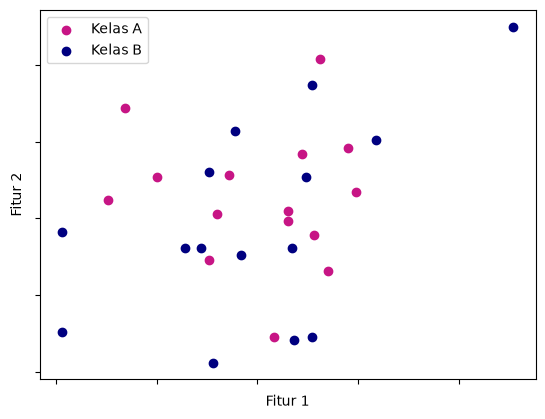

In [4]:
import matplotlib.pyplot as plt

colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Gunakan groupby('Label') tanpa kurung siku agar get_group('Kelas A') tidak KeyError di pandas baru
gb = df_label.groupby('Label')
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

In [5]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

mnb = MultinomialNB()

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

mnb.fit(X_train, y_train)

y_train_pred = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)
y_test_pred = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.5714285714285714
Hasil akurasi data test: 0.4444444444444444


In [ ]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()

gnb.fit(X_train, y_train)

y_train_pred_gnb = gnb.predict(X_train)
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

y_test_pred_gnb = gnb.predict(X_test)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.6190476190476191
Hasil akurasi data test (Gaussian): 0.4444444444444444
